# Laboratorium 1. Fisher i liniowy SVM

**Czas:** około 90 minut &emsp; **Punkty:** 6

**Imię i nazwisko:** Michał Pietruszyński 
**Numer albumu / grupa:** 337731



## 0. Przygotowanie

Wybierz środowisko **Python 3** i uruchom poniższą komórkę. Sprawdza ona
biblioteki potrzebne podczas dzisiejszych zajęć. Jeśli pojawi się błąd,
zgłoś go prowadzącemu przed rozpoczęciem ćwiczeń.

Potrzebne biblioteki: **NumPy, Matplotlib, scikit-learn**.

**Zasada pracy z danymi:** najpierw dzielimy dane. Parametry modelu i skalowania
wyznaczamy tylko na zbiorze treningowym. Walidacja służy porównywaniu ustawień,
a test — końcowej ocenie ustalonego modelu. Nie dobieramy `C` ani `gamma` na teście.


In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt
import sklearn

from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

plt.rcParams.update(
    {"figure.figsize": (6, 4), "axes.grid": True, "grid.alpha": 0.2, "font.size": 11}
)
KOLORY = ["#2878B5", "#D95319", "#498A38"]
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

# Prosty test najważniejszych bibliotek
test_X = np.array([[0.0, 0.0], [0.2, 0.1], [1.0, 1.0], [1.2, 0.9]])
test_y = np.array([0, 0, 1, 1])
test_model = LinearDiscriminantAnalysis().fit(test_X, test_y)
assert np.array_equal(test_model.predict(test_X), test_y)
test_fig = plt.figure()
plt.close(test_fig)
print("Środowisko działa poprawnie.")

Python: 3.14.3
NumPy: 2.5.4
scikit-learn: 1.9.1
Środowisko działa poprawnie.


In [2]:
def dane_dwie_klasy(seed=42, n_na_klase=80):
    rng = np.random.default_rng(seed)
    kowariancja = np.array([
        [1.0, 0.75],
        [0.75, 1.2]
    ])
    # 1.0, 0.95
    # 0.95, 1.0
    X0 = rng.multivariate_normal([-1.0, 0.0], kowariancja, n_na_klase)
    X1 = rng.multivariate_normal([1.0, 0.8], kowariancja, n_na_klase)
    return np.vstack([X0, X1]), np.repeat([0, 1], n_na_klase)


def rysuj_klasy(X, y, ax, nazwy=None):
    for k in np.unique(y):
        ax.scatter(
            *X[y == k].T,
            s=30,
            color=KOLORY[int(k)],
            alpha=0.8,
            label=f"Klasa {k}" if nazwy is None else nazwy[int(k)],
        )
    ax.set(xlabel="$x_1$", ylabel="$x_2$")
    ax.legend()

Trening: (112, 2) Test: (48, 2)


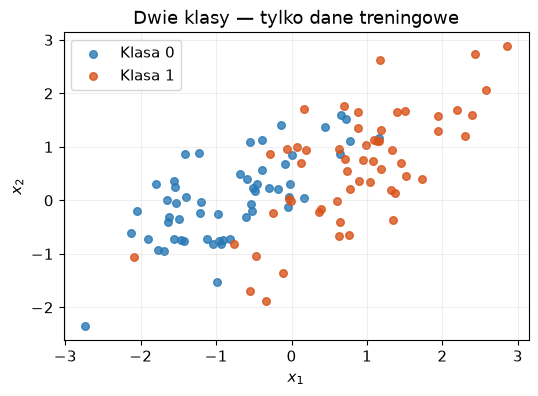

In [3]:
X, y = dane_dwie_klasy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print("Trening:", X_train.shape, "Test:", X_test.shape)
fig, ax = plt.subplots()
rysuj_klasy(X_train, y_train, ax)
ax.set_title("Dwie klasy — tylko dane treningowe")
plt.show()

## 1. Metoda Fishera: dobry kierunek rzutu

Chcemy zastąpić wektor cech $x$ jedną liczbą $z=a^T x$. Dobry kierunek $a$
oddala średnie klas po rzucie i ogranicza rozrzut wewnątrz klas.
Dla klas $0,1$ oznaczmy średnie przez $\mu_0,\mu_1$, liczebności przez $n_0,n_1$,
a ich macierze kowariancji z próby przez $S_0,S_1$. Zgodnie z wykładem:

$$W=\frac{(n_0-1)S_0+(n_1-1)S_1}{n_0+n_1-2}, \qquad
J(a)=\frac{[a^T(\mu_1-\mu_0)]^2}{a^TWa}.$$

Kierunek maksymalizujący $J$ spełnia
$$a\propto W^{-1}(\mu_1-\mu_0).$$

Liczy się kierunek, a nie długość $a$. W kodzie rozwiązujemy układ
`np.linalg.solve(W, mu1 - mu0)`, zamiast jawnie odwracać macierz.
W tych dwuwymiarowych danych $W$ jest odwracalna.

Sam rzut Fishera nie wyznacza progu. Tutaj przyjmujemy środek między rzutami średnich:
$$t=\tfrac12 a^T(\mu_0+\mu_1),\qquad
\widehat y=\begin{cases}0,&a^Tx<t,\\1,&a^Tx\geq t.\end{cases}$$

Orientujemy $a$ od klasy 0 do 1. Taka reguła odpowiada LDA przy wspólnej
kowariancji, rozkładach normalnych i równych prawdopodobieństwach klas oraz kosztach błędów.
Samo kryterium Fishera można obliczać także bez założenia normalności.


### Ćwiczenie A — uzupełnij klasyfikator (wspólnie)

Uzupełnij średnie, macierz $W$, kierunek $a$ i próg $t$ według wzorów powyżej.
`mean(axis=0)` liczy średnią każdej cechy, `np.cov(..., rowvar=False)` — macierz
kowariancji cech. Funkcję `fisher_fit` dopasujemy wyłącznie do treningu.


In [11]:
def fisher_fit(X, y):
    X0, X1 = X[y == 0], X[y == 1]
    n0, n1 = len(X0), len(X1)

    mu0 = X0.mean(axis=0)  # TODO A1
    mu1 = X1.mean(axis=0)  # TODO A2

    S0 = np.cov(X0, rowvar=False)
    S1 = np.cov(X1, rowvar=False)
    W = ((n0-1)*S0+(n1-1)*S1)/(n0+n1-2) # TODO A3

    a = np.linalg.solve(W, mu1-mu0)  # TODO A4
    a = a / np.linalg.norm(a)  # normalizacja ułatwia rysowanie
    t = a@(mu0+mu1)/2  # TODO A5
    return a, t


def fisher_predict(X, a, t):
    return ((X @ a) >= t).astype(int)


a_f, t_f = fisher_fit(X_train, y_train)
print("Kierunek:", a_f.round(3), t_f)


Kierunek: [ 0.918 -0.398] -0.11609317101679924


In [9]:
y_pred_f = fisher_predict(X_test,a_f,t_f)  # TODO A6
print(f"Accuracy na teście: {accuracy_score(y_test, y_pred_f):.3f}")


Accuracy na teście: 0.896


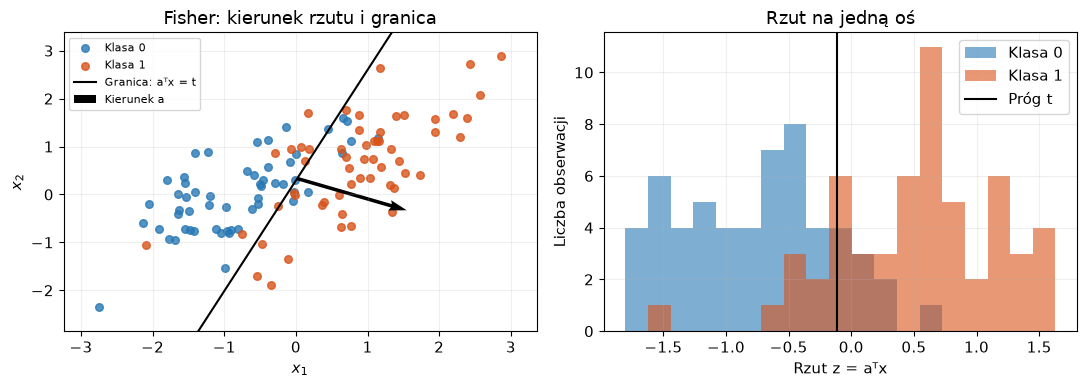

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rysuj_klasy(X_train, y_train, axes[0])
punkt_na_granicy = t_f * a_f  # ||a_f|| = 1
kierunek_granicy = np.array([-a_f[1], a_f[0]])
odcinek = punkt_na_granicy + np.linspace(-6, 6, 100)[:, None] * kierunek_granicy
axes[0].plot(*odcinek.T, "k-", label="Granica: aᵀx = t")
srodek = X_train.mean(axis=0)
axes[0].quiver(
    *srodek,
    *a_f,
    angles="xy",
    scale_units="xy",
    scale=0.6,
    color="black",
    label="Kierunek a",
)
axes[0].set(
    xlim=(X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5),
    ylim=(X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5),
    title="Fisher: kierunek rzutu i granica",
)
axes[0].legend(fontsize=8)
z_train = X_train @ a_f
bins = np.linspace(z_train.min(), z_train.max(), 20)
for k in (0, 1):
    axes[1].hist(
        z_train[y_train == k], bins=bins, alpha=0.6, color=KOLORY[k], label=f"Klasa {k}"
    )
axes[1].axvline(t_f, color="black", label="Próg t")
axes[1].set(xlabel="Rzut z = aᵀx", ylabel="Liczba obserwacji", title="Rzut na jedną oś")
axes[1].legend()
plt.tight_layout()
plt.show()


**Do omówienia:** czy histogramy całkowicie się rozdzieliły? Co stanie się
z przewidywaniami, gdy pomnożymy jednocześnie $a$ i $t$ przez dodatnią liczbę 10?

### Notatnik
>
> …

`accuracy` to odsetek poprawnych przewidywań. W zrównoważonych danych jest
wygodnym pierwszym miernikiem; wynik na treningu nie zastępuje wyniku na nowych danych.


### Więcej niż dwie klasy — krótki pokaz

Dla $g$ klas i $p$ cech można uzyskać najwyżej $\min(p,g-1)$ kierunków
dyskryminacyjnych. Na wykładzie odpowiadają one największym wartościom własnym
$W^{-1}B$, gdzie $B$ opisuje rozrzut średnich klas. Biblioteka wykonuje te obliczenia za nas.

Iris ma 4 cechy i 3 klasy, więc pokażemy rzut na 2 osie. To **wizualizacja danych
użytych do dopasowania**, a nie pomiar jakości klasyfikatora na teście.
Nie trzeba implementować rozkładu własnego.


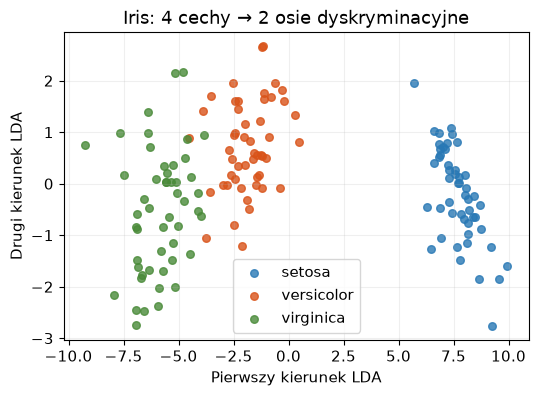

In [12]:
iris = load_iris()
lda = LinearDiscriminantAnalysis(n_components=2)
Z_iris = lda.fit_transform(iris.data, iris.target)
fig, ax = plt.subplots()
rysuj_klasy(Z_iris, iris.target, ax, iris.target_names)
ax.set(
    xlabel="Pierwszy kierunek LDA",
    ylabel="Drugi kierunek LDA",
    title="Iris: 4 cechy → 2 osie dyskryminacyjne",
)
plt.show()


## 2. SVM liniowy: granica i margines

SVM szuka granicy $f(x)=w^Tx+b=0$. Znak $f(x)$ wskazuje klasę.
Dla etykiet $y_i\in\{-1,+1\}$ twardy margines oznacza rozwiązanie:

$$\min_{w,b}\frac12\|w\|^2 \quad\text{przy}\quad y_i(w^Tx_i+b)\geq1.$$

Proste $f(x)=-1$ i $f(x)=+1$ ograniczają pas o szerokości $2/\|w\|$.
W dwóch wymiarach granica jest prostą, a w większej liczbie wymiarów — hiperpłaszczyzną.
**Wektory podpierające** to obserwacje z niezerowymi współczynnikami w rozwiązaniu SVM;
w przypadku twardego marginesu leżą na brzegach pasa.

Nasze klasy mogą się nakładać, dlatego od początku używamy `SVC`, który dopuszcza
**miękki margines** (następna sekcja). Wtedy wektory podpierające mogą też leżeć
wewnątrz marginesu lub być błędnie sklasyfikowane.
Biblioteka przyjmuje nasze etykiety `0, 1` bez ręcznego kodowania do `−1, +1`.

SVM zależy od skali cech. `StandardScaler` odejmuje średnią i dzieli przez
odchylenie standardowe każdej cechy. `make_pipeline(StandardScaler(), SVC(...))`
łączy skalowanie i klasyfikację; wywołanie `fit` na treningu dopasowuje oba kroki.


### Ćwiczenie B — dopasuj liniowy SVM (wspólnie)

Wywołaj konstruktor `SVC` z argumentami `kernel="linear"` i `C=1.0`.
Gotowy kod połączy klasyfikator ze skalowaniem; następnie uzupełnij
przewidywania na teście.

Przydatny schemat API: `model.fit(X_train, y_train)` uczy model,
`model.predict(X_test)` przewiduje etykiety, a `model.score(X_test, y_test)` zwraca accuracy.
`model.named_steps["svc"]` udostępnia dopasowany SVC z pipeline.


In [13]:
def rysuj_svm(model, X, y, ax, tytul):
    """Model to dopasowany Pipeline: StandardScaler + binarny SVC."""
    dol, gora = X.min(axis=0) - 0.6, X.max(axis=0) + 0.6
    xx, yy = np.meshgrid(
        np.linspace(dol[0], gora[0], 180), np.linspace(dol[1], gora[1], 180)
    )
    siatka = np.column_stack([xx.ravel(), yy.ravel()])
    pred = model.predict(siatka).reshape(xx.shape)
    ax.contourf(
        xx,
        yy,
        pred,
        levels=[-0.5, 0.5, 1.5],
        alpha=0.12,
        cmap=ListedColormap(KOLORY[:2]),
    )
    f = model.decision_function(siatka).reshape(xx.shape)
    ax.contour(
        xx,
        yy,
        f,
        levels=[-1, 0, 1],
        colors="black",
        linestyles=["--", "-", "--"],
        linewidths=1,
    )
    rysuj_klasy(X, y, ax)
    # SVC widzi cechy standaryzowane; na wykresie pokazujemy oryginalne jednostki.
    sv = model.named_steps["standardscaler"].inverse_transform(
        model.named_steps["svc"].support_vectors_
    )
    ax.scatter(
        *sv.T,
        s=85,
        facecolors="none",
        edgecolors="black",
        linewidths=0.8,
        label="Wektory podpierające",
    )
    uchwyty, etykiety = ax.get_legend_handles_labels()
    uchwyty += [
        Line2D([0], [0], color="black"),
        Line2D([0], [0], color="black", linestyle="--"),
    ]
    ax.legend(uchwyty, etykiety + ["f(x) = 0", "f(x) = ±1"], fontsize=8)
    ax.set(title=tytul, xlim=(dol[0], gora[0]), ylim=(dol[1], gora[1]))


In [ ]:
klasyfikator_liniowy = ...  # TODO B1
svm_liniowy = make_pipeline(StandardScaler(), klasyfikator_liniowy)
svm_liniowy.fit(X_train, y_train)

y_pred_svm = ...  # TODO B2
print(f"Accuracy na teście: {accuracy_score(y_test, y_pred_svm):.3f}")
svc = svm_liniowy.named_steps["svc"]
print("Liczba wektorów podpierających w klasach:", svc.n_support_)
print("Łącznie wektorów podpierających:", len(svc.support_))

fig, ax = plt.subplots()
rysuj_svm(svm_liniowy, X_train, y_train, ax, "SVM liniowy, C = 1")
plt.show()


In [ ]:
w = svc.coef_[0]
b = svc.intercept_[0]
szerokosc = ...  # TODO B3
print("w =", w.round(3), "b =", round(b, 3))
print(f"Szerokość pasa w przestrzeni standaryzowanej: {szerokosc:.3f}")


**Do omówienia:** czy wszystkie zakreślone punkty leżą na przerywanych liniach?
Dlaczego przy miękkim marginesie nie musi tak być?

### Notatnik
>
> …

`coef_` dotyczy cech **po standaryzacji**, więc obliczone $2/\|w\|$ jest odległością
w tej przestrzeni. Wykres pokazuje oryginalne jednostki. `decision_function`
zwraca wartość funkcji decyzyjnej, a nie prawdopodobieństwo klasy.


## 3. Miękki margines i parametr C

Gdy klas nie da się idealnie rozdzielić, dopuszczamy naruszenia marginesu $\xi_i$:

$$\min_{w,b,\xi}\frac12\|w\|^2+C\sum_i\xi_i,
\qquad y_i(w^Tx_i+b)\geq1-\xi_i,\quad \xi_i\geq0.$$

- **Małe `C`**: mniejsza kara za naruszenia, silniejsza regularyzacja.
- **Duże `C`**: większa kara za naruszenia; model silniej stara się spełnić ograniczenia treningowe.

Naruszenie marginesu nie zawsze oznacza błąd klasyfikacji: punkt może być po
właściwej stronie granicy, ale zbyt blisko niej. Większe `C` nie gwarantuje lepszej
accuracy na nowych danych ani stałego kierunku zmiany liczby wektorów podpierających.

### Ćwiczenie C — porównaj trzy wartości C (wspólnie)

Wydzielamy **walidację z treningu**. Uzupełnij tworzenie pipeline w pętli
dla `C = 0.01, 1, 100`. Tabelę i wykresy tworzy gotowy kod. Test pozostaje poza eksperymentem.


In [ ]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=7
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
print(
    f"{'C':>7} {'acc_train':>11} {'acc_val':>9} {'liczba SV':>11} {'pas (stand.)':>14}"
)
for C, ax in zip([0.01, 1.0, 100.0], axes):
    model_c = ...  # TODO C1
    model_c.fit(X_fit, y_fit)
    svc_c = model_c.named_steps["svc"]
    pas_c = 2 / np.linalg.norm(svc_c.coef_[0])
    print(
        f"{C:7.2f} {model_c.score(X_fit, y_fit):11.3f} "
        f"{model_c.score(X_val, y_val):9.3f} {len(svc_c.support_):11d} {pas_c:14.3f}"
    )
    rysuj_svm(model_c, X_fit, y_fit, ax, f"SVM liniowy, C = {C:g}")
plt.tight_layout()
plt.show()


**Do omówienia:** jak zmienia się szerokość pasa? Czy najlepszy wynik treningowy
oznacza najlepszy wynik walidacyjny? Oprzyj odpowiedź na tabeli — nie zakładaj,
że accuracy musi zmieniać się monotonicznie.

### Notatnik
>
> …


### Przed pracą samodzielną

| Metoda / ustawienie | Co robi? |
|:--|:--|
| Fisher | Wyznacza rzut rozdzielający średnie względem rozrzutu wewnątrz klas |
| SVM liniowy | Wyznacza liniową granicę przez optymalizację marginesu i kary za naruszenia |
| `C` | Określa siłę kary za naruszenia marginesu |
| `StandardScaler` w pipeline | Dopasowuje skalowanie tylko na danych przekazanych do `fit` |

Pomoc do użytego API: [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html),
[LDA](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html),
[standaryzacja](https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling).


## Zadania końcowe

Pracuj samodzielnie przez około 30 minut. W każdym zadaniu podejmij potrzebne
decyzje, zaimplementuj je i krótko uzasadnij w komentarzu lub polu notatek.
Pozostaw widoczne wyniki działania kodu.

Łącznie możesz otrzymać **6 punktów**. Oceniane są poprawność i działanie kodu,
rozumienie użytych metod, zasadność decyzji oraz interpretacja wyniku. Nie liczy
się samo osiągnięcie jak najwyższej wartości accuracy. Skalowanie i model
dopasowuj bez korzystania z danych przeznaczonych do końcowej oceny.


### Zadanie 1. Fisher na nowych danych

Wygeneruj dane funkcją `dane_dwie_klasy(seed=13, n_na_klase=60)` i zbuduj
dla nich klasyfikator Fishera. Podziel dane na zestawy do uczenia
i oceny, uzasadnij go oraz wyjaśnij rolę macierzy $W$ w otrzymanym rozwiązaniu.


In [ ]:
# Rozwiązanie zadania 1


### Zadanie 2. Zmień C i odczytaj margines

Porównaj liniowy SVM dla `C=0.05` i `C=5.0` na danych z funkcji
`dane_dwie_klasy(seed=21, n_na_klase=70)`. Wytrenuj algorytm, a następnie porównaj accuracy i szerokość marginesów.
Wyjaśnij, jak wartość `C` wpłynęła na otrzymane wyniki.


In [ ]:
# Rozwiązanie zadania 2


### Zadanie 3. Skala cech a liniowy SVM

Wygeneruj dane funkcją `dane_dwie_klasy(seed=29, n_na_klase=70)`
i pomnóż drugą cechę przez 100. Porównaj liniowy SVM ze skalowaniem
i bez niego, sam wybierz uczciwy sposób oceny na nowych danych oraz
wyjaśnij wpływ jednostek cech na wynik.


In [ ]:
# Rozwiązanie zadania 3


## Przed oddaniem

Uruchom notatnik od początku i sprawdź, czy wszystkie komórki wykonują się
BEZ BŁĘDÓW. Zapisz kod, jego wyniki oraz swoje uzasadnienia i wnioski.
